# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [2]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Климчук Юрій'      # прізвище та ім'я
GROUP        = 'СШІ-31'      # шифр групи, наприклад СШІ-31
NUMBER       = 9       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Климчук Юрій | СШІ-31 | номер 9


In [3]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 9   ·   Климчук Юрій   ·   СШІ-31

   Ринок:  Rivne
   Товар:  ковбаса   (у наборі даних: Meat (mixed, sausage) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [5]:
import pandas as pd

df = pd.read_csv("ціни_україна_2014_2017.csv")

full_grid = pd.date_range(start="2014-03-01", end="2017-12-01", freq="MS")
df_series = df[(df["ринок"] == MARKET) & (df["товар"] == GOOD)].copy()
df_series["date"] = pd.to_datetime(
    df_series["рік"].astype(str) + "-" + df_series["місяць"].astype(str).str.zfill(2) + "-01"
)

df_prepared = pd.merge(
    pd.DataFrame({"date": full_grid}), df_series, on="date", how="left"
).sort_values("date")

total_months = len(df_prepared)
measured_months = df_prepared["ціна"].notna().sum()
missing_dates = df_prepared[df_prepared["ціна"].isna()]["date"]

print(f"Всього місяців у сітці: {total_months}")
print(f"Місяців із вимірами: {measured_months}")
print(f"Місяці з пропусками: {[d.strftime('%Y-%m') for d in missing_dates]}")

aug_2017_all = df[(df["рік"] == 2017) & (df["місяць"] == 8)]
print(f"Записів за серпень 2017 у базі: {len(aug_2017_all)}")

Всього місяців у сітці: 46
Місяців із вимірами: 45
Місяці з пропусками: ['2017-08']
Записів за серпень 2017 у базі: 0


**Висновок до завдання 1:**

*У результаті підготовки часового ряду зафіксовано 46 місяців у повному часовому інтервалі з березня 2014 року по грудень 2017 року. Фактичні значення ціни присутні для 45 місяців, а єдиний пропуск припадає на серпень 2017 року. Цей пропуск має системний характер для всієї бази даних, оскільки за серпень 2017 року дані відсутні для всіх товарів та регіонів.*

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [6]:
# Завдання 2. Заповнення пропуску
val_ffill = df_prepared["ціна"].ffill().loc[df_prepared["date"] == "2017-08-01"].values[0]
val_linear = df_prepared["ціна"].interpolate(method="linear").loc[df_prepared["date"] == "2017-08-01"].values[0]
val_bfill = df_prepared["ціна"].bfill().loc[df_prepared["date"] == "2017-08-01"].values[0]

print(f"Перенесення останнього значення: {val_ffill:.2f}")
print(f"Лінійна інтерполяція: {val_linear:.2f}")
print(f"Перенесення наступного значення: {val_bfill:.2f}")

df_prepared["ціна"] = df_prepared["ціна"].interpolate(method="linear")

Перенесення останнього значення: 62.67
Лінійна інтерполяція: 64.61
Перенесення наступного значення: 66.54


**Висновок до завдання 2:**

*Для заповнення пропуску за серпень 2017 року розраховано значення трьома способами. Перенесення останнього значення дає 62.67 грн, лінійна інтерполяція дає 64.61 грн, а перенесення наступного значення дає 66.54 грн. Для використання обрано лінійну інтерполяцію, оскільки ціна у цей період мала чітку тенденцію до зростання з липня по вересень, і рівномірний поділ різниці між суміжними місяцями найкраще відображає реальну динаміку. Заповнювати пропуски неприпустимо тоді, коли спостереження припиняються повністю через структурні зміни або втрату доступу до об'єкта дослідження. Прикладом із цього датасету є АР Крим та місто Севастополь, які зникають із вибірки наприкінці 2014 року. Штучне заповнення даних для цих регіонів за 2015-2017 роки створювало б фальшиві показники для територій, де збір цінової інформації більше не проводився.*

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

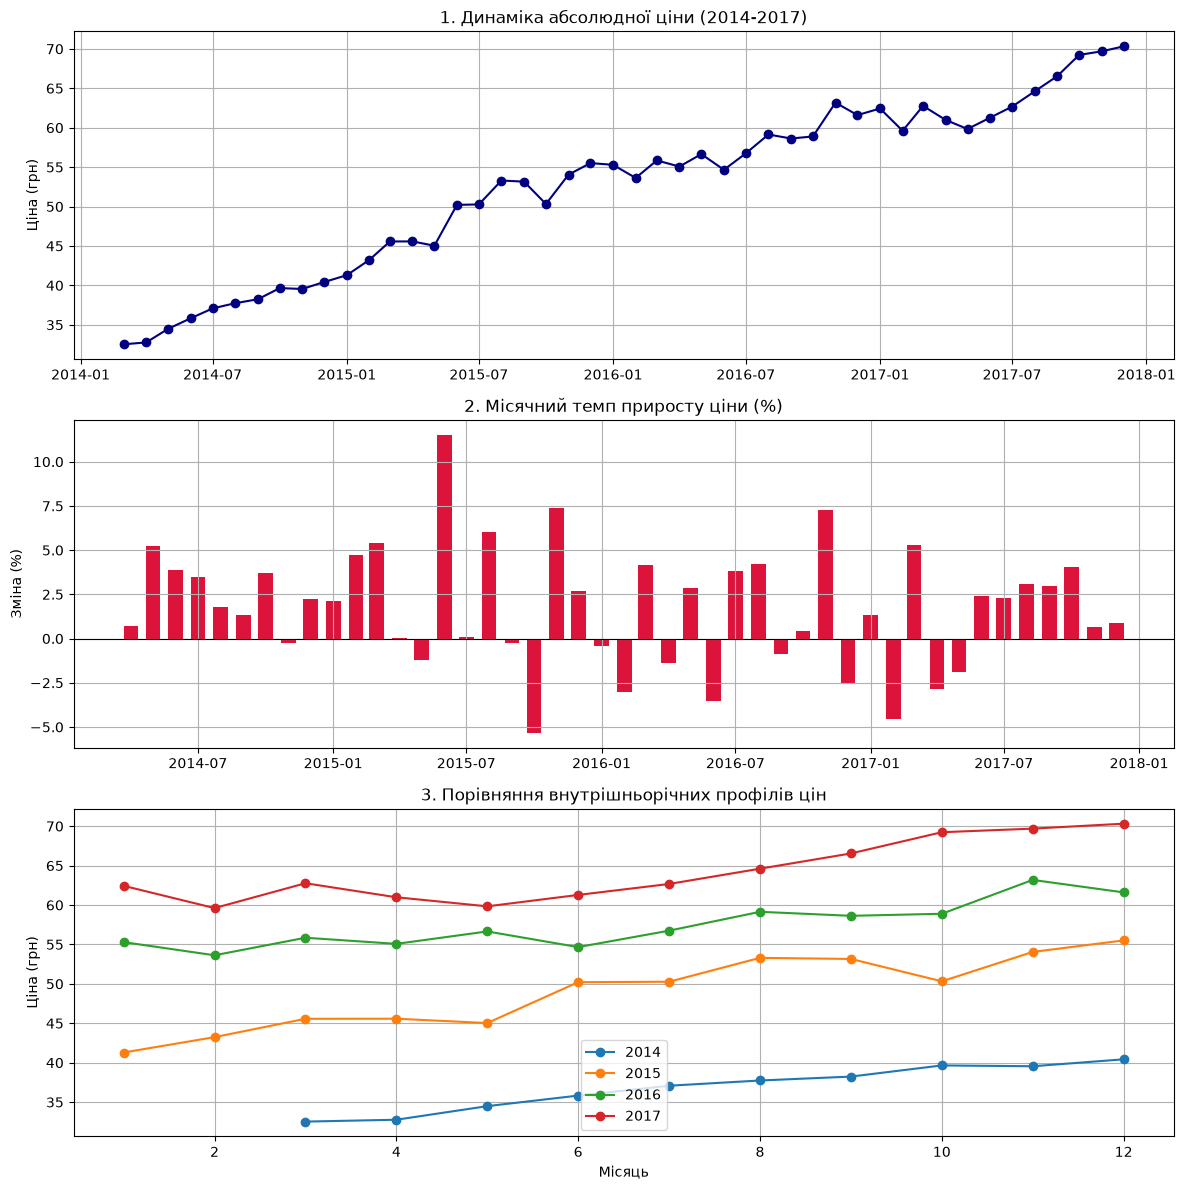

In [7]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

df_prepared["pct_change"] = df_prepared["ціна"].pct_change() * 100
df_prepared["year"] = df_prepared["date"].dt.year
df_prepared["month"] = df_prepared["date"].dt.month

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

axes[0].plot(df_prepared["date"], df_prepared["ціна"], marker="o", color="navy")
axes[0].set_title("1. Динаміка абсолюдної ціни (2014-2017)")
axes[0].set_ylabel("Ціна (грн)")
axes[0].grid(True)

axes[1].bar(df_prepared["date"], df_prepared["pct_change"], width=20, color="crimson")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("2. Місячний темп приросту ціни (%)")
axes[1].set_ylabel("Зміна (%)")
axes[1].grid(True)

for year, group in df_prepared.groupby("year"):
    axes[2].plot(group["month"], group["ціна"], marker="o", label=str(year))
axes[2].set_title("3. Порівняння внутрішньорічних профілів цін")
axes[2].set_xlabel("Місяць")
axes[2].set_ylabel("Ціна (грн)")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Висновок до завдання 3:**

*Перелік графіків:* 
 - Перший графік відповідає на питання про загальний довгостроковий тренд ціни. Обрано лінійну геометрію з лінійною шкалою, оскільки вона найкраще відображає безперервність часового ряду та загальну тенденцію зростання. 
 - Другий графік відповідає на питання, у які саме місяці відбувалися найгостріші стрибки цін. Обрано стовпчасту геометрію відносно нульової позначки, бо вона дозволяє чітко порівнювати дискретні місячні зміни між собою.
 - Третій графік відповідає на питання про наявність внутрішньорічної сезонності. Обрано накладання лінійних профілів за кожний рік від 1 до 12 місяця, що дає змогу порівняти поведінку цін в однакові місяці різних років. Неочікуваною знахідкою виявилося те, що у 2016 році ціна майже не зростала і тривалий час перебувала у стані плато, тоді як найбільший за весь період одноразовий стрибок ціни на 11.5% стався у червні 2015 року, після чого восени того ж року відбулося тимчасове здешевлення.*

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

Сила тренду (F_T): 0.9946
Сила сезонності (F_S): 0.7782


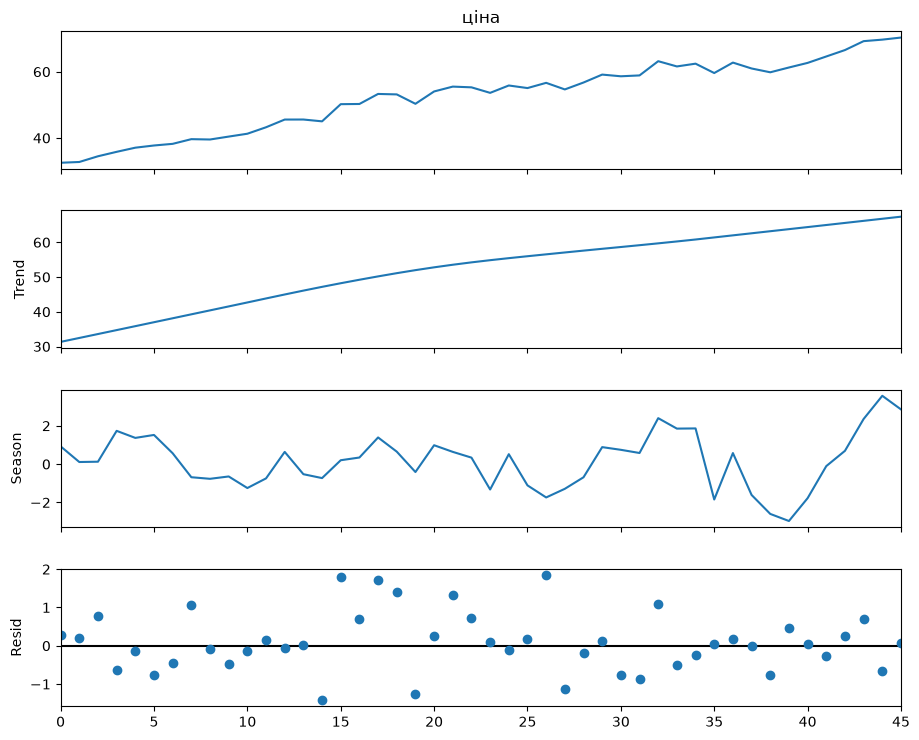

In [9]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL
import numpy as np

stl = STL(df_prepared["ціна"], period=12)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(10, 8)

var_R = np.var(res.resid)
var_TR = np.var(res.trend + res.resid)
var_SR = np.var(res.seasonal + res.resid)

F_T = max(0, 1 - var_R / var_TR)
F_S = max(0, 1 - var_R / var_SR)

print(f"Сила тренду (F_T): {F_T:.4f}")
print(f"Сила сезонності (F_S): {F_S:.4f}")

**Висновок до завдання 4:**

*У результаті розкладання методом STL отримано показник сили тренду F_T = 0.9946 та показник сили сезонності F_S = 0.7782. Оскільки сила сезонності перевищує загальноприйняте порогове значення 0.6, у досліджуваному часовому ряді присутня виражена сезонна складова. Це означає, що коливання цін протягом року мають регулярний повторюваний характер і їх необхідно враховувати під час подальшого моделювання.*

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

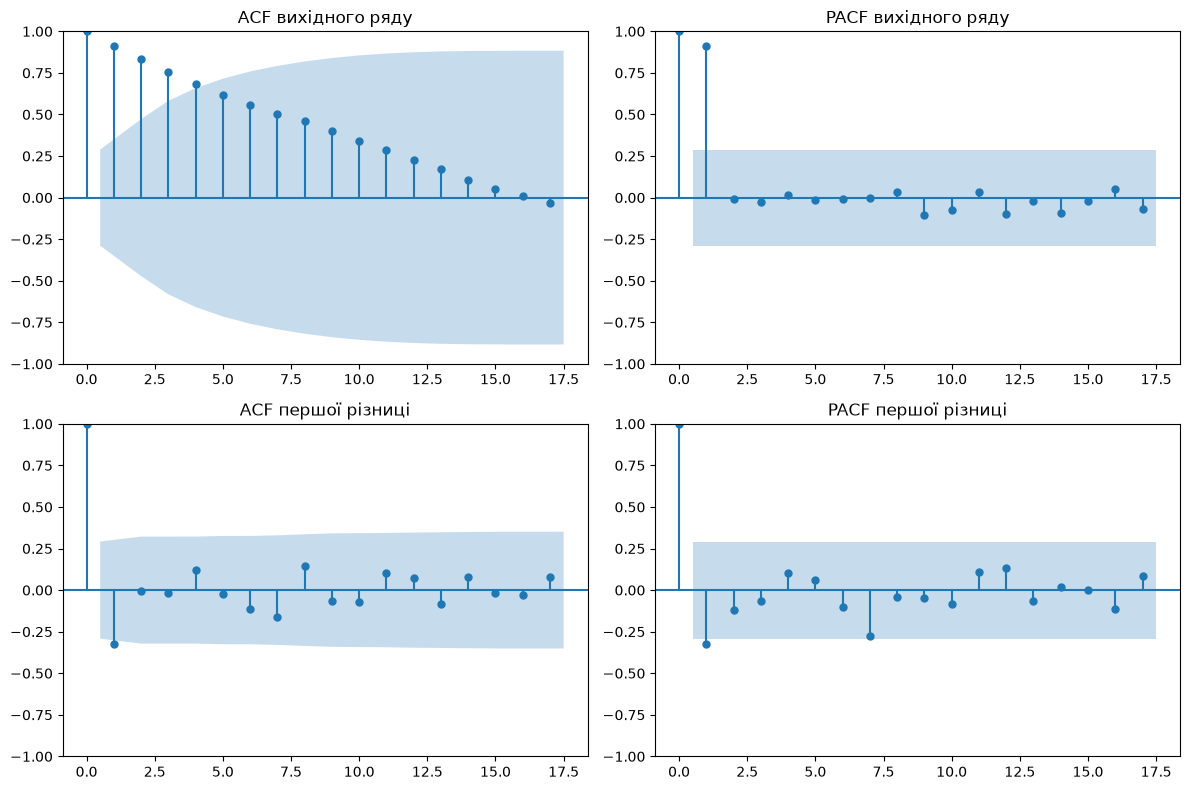

          Ряд p-value ADF p-value KPSS
 Вихідний ряд      0.7548       0.0100
Перша різниця      0.0000       0.1000


In [10]:
# Завдання 5. Стаціонарність
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')

series_orig = df_prepared["ціна"]
series_diff = series_orig.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_acf(series_orig, ax=axes[0, 0], title="ACF вихідного ряду")
plot_pacf(series_orig, ax=axes[0, 1], title="PACF вихідного ряду")
plot_acf(series_diff, ax=axes[1, 0], title="ACF першої різниці")
plot_pacf(series_diff, ax=axes[1, 1], title="PACF першої різниці")

plt.tight_layout()
plt.show()

p_adf_orig = adfuller(series_orig)[1]
p_kpss_orig = kpss(series_orig)[1]
p_adf_diff = adfuller(series_diff)[1]
p_kpss_diff = kpss(series_diff)[1]

res_table = pd.DataFrame({
    "Ряд": ["Вихідний ряд", "Перша різниця"],
    "p-value ADF": [f"{p_adf_orig:.4f}", f"{p_adf_diff:.4f}"],
    "p-value KPSS": [f"{p_kpss_orig:.4f}", f"{p_kpss_diff:.4f}"]
})

print(res_table.to_string(index=False))

**Висновок до завдання 5:**

*Результати тестування стаціонарності свідчать про нестаціонарність вихідного ряду. Для вихідного ряду p-значення тесту ADF становить 0.7548, що більше за 0.05 i не дозволяє відхилити гіпотезу про наявність одиничного кореня, а p-значення тесту KPSS становить 0.0100, що менше за 0.05 i вказує на нестаціонарність. Для першої різниці p-значення ADF становить 0.0000, а p-значення KPSS становить 0.1000, що підтверджує стаціонарність різницевого ряду. Обидва тести повністю узгоджуються між собою як для вихідних даних, так і після диференціювання. Для приведення ряду до стаціонарного вигляду достатньо одного диференціювання (порядок integrated d = 1).*

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [11]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
n_folds = 7
horizon = 3
start_train_size = len(df_prepared) - n_folds * horizon

def naive_forecast(train, h):
    return np.full(h, train[-1])

def seasonal_naive_forecast(train, h, season=12):
    return np.array([train[-season + i] for i in range(h)])

def mean_forecast(train, h):
    return np.full(h, np.mean(train))

def drift_forecast(train, h):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return np.array([train[-1] + (i + 1) * slope for i in range(h)])

methods = {
    "Наївний": naive_forecast,
    "Сезонний наївний": seasonal_naive_forecast,
    "Середнє": mean_forecast,
    "Дрейф": drift_forecast
}

cv_results = {m: {"mae": [], "rmse": [], "mape": []} for m in methods}

for fold in range(n_folds):
    train_end = start_train_size + fold * horizon
    train = df_prepared["ціна"].iloc[:train_end].values
    test = df_prepared["ціна"].iloc[train_end:train_end + horizon].values
    
    for name, func in methods.items():
        pred = func(train, horizon)
        err = test - pred
        cv_results[name]["mae"].extend(np.abs(err))
        cv_results[name]["rmse"].extend(err**2)
        cv_results[name]["mape"].extend(np.abs(err / test) * 100)

metrics_cv_df = pd.DataFrame({
    name: {
        "MAE": np.mean(res["mae"]),
        "RMSE": np.sqrt(np.mean(res["rmse"])),
        "MAPE (%)": np.mean(res["mape"])
    }
    for name, res in cv_results.items()
}).T

print("Результати ретроспективної перевірки (7 фолдів х 3 кроки)")
print(metrics_cv_df.round(4))

train_split = df_prepared["ціна"].iloc[:34].values
test_split = df_prepared["ціна"].iloc[34:].values
h_split = len(test_split)

split_results = {}
for name, func in methods.items():
    pred = func(train_split, h_split)
    err = test_split - pred
    split_results[name] = {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err**2)),
        "MAPE (%)": np.mean(np.abs(err / test_split)) * 100
    }

metrics_split_df = pd.DataFrame(split_results).T
print("\nРезультати для звичайного поділу 75/25 (12 кроків)")
print(metrics_split_df.round(4))

Результати ретроспективної перевірки (7 фолдів х 3 кроки)
                      MAE     RMSE  MAPE (%)
Наївний            2.4213   2.7982    3.8705
Сезонний наївний   7.0360   7.3067   11.4367
Середнє           13.4466  13.7123   21.6432
Дрейф              2.0572   2.4179    3.3777

Результати для звичайного поділу 75/25 (12 кроків)
                      MAE     RMSE  MAPE (%)
Наївний            3.3461   4.5086    4.9865
Сезонний наївний   6.7183   6.9303   10.3983
Середнє           15.7755  16.2055   24.3400
Дрейф              3.1620   3.6686    5.0396


**Висновок до завдання 6:**

*За результатами ретроспективної перевірки з рухомим початком кращі показники показала модель дрейфу з показниками MAE = 2.06 грн, RMSE = 2.42 грн та MAPE = 3.38%. Друге місце посів наївний прогноз з MAE = 2.42 грн, далі сезонний наївний з MAE = 7.04 грн, а найгіршим виявилося середнє значення з MAE = 13.45 грн. Модель дрейфу виявилася найкращою, оскільки досліджуваний ряд цін має стійкий виражений тренд зростання. Модель дрейфу враховує цей середній темп зростання та продовжує його у майбутнє. Наївний прогноз припускає зафіксовану ціну і тому запізнюється, а модель середнього суттєво занижує прогноз через врахування застарілих низьких цін 2014 року. При звичайному поділі 75/25 помилка MAE для моделі дрейфу зростає до 3.16 грн, що у 1.54 рази більше за оцінку на ретроспективній перевірці. Це пояснюється тим, що при поділі 75/25 горизонт прогнозування становить 12 місяців уперед, і з віддаленням у часі помилка накопичується.*

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

ARIMA(1,1,1) MAE: 2.3375
ARIMA(1,1,1) RMSE: 2.7258
ARIMA(1,1,1) MAPE: 3.7444%


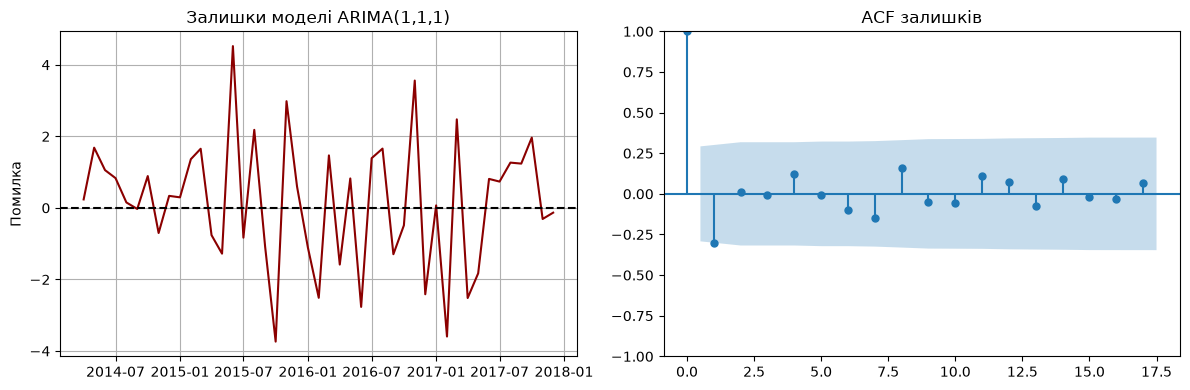

In [12]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf

arima_errors = []
arima_y_true = []

for fold in range(n_folds):
    train_end = start_train_size + fold * horizon
    train = df_prepared["ціна"].iloc[:train_end].values
    test = df_prepared["ціна"].iloc[train_end:train_end + horizon].values
    
    model = ARIMA(train, order=(1, 1, 1)).fit()
    pred = model.forecast(steps=horizon)
    
    arima_errors.extend(test - pred)
    arima_y_true.extend(test)

arima_errors = np.array(arima_errors)
arima_y_true = np.array(arima_y_true)

mae_arima = np.mean(np.abs(arima_errors))
rmse_arima = np.sqrt(np.mean(arima_errors**2))
mape_arima = np.mean(np.abs(arima_errors / arima_y_true)) * 100

print(f"ARIMA(1,1,1) MAE: {mae_arima:.4f}")
print(f"ARIMA(1,1,1) RMSE: {rmse_arima:.4f}")
print(f"ARIMA(1,1,1) MAPE: {mape_arima:.4f}%")

full_model = ARIMA(df_prepared["ціна"], order=(1, 1, 1)).fit()
residuals = full_model.resid[1:]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df_prepared["date"][1:], residuals, color="darkred")
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Залишки моделі ARIMA(1,1,1)")
axes[0].set_ylabel("Помилка")
axes[0].grid(True)

plot_acf(residuals, ax=axes[1], title="ACF залишків")
plt.tight_layout()
plt.show()

**Висновок до завдання 7:**

*Для моделі ARIMA(1,1,1) на ретроспективній перевірці отримано показники MAE = 2.34 грн, RMSE = 2.73 грн та MAPE = 3.74%. Виходячи з аналізу графіків ACF та PACF першої різниці у завданні 5, самостійно доцільніше було б обрати простішу модель ARIMA(0,1,1) або ARIMA(1,1,0), оскільки від'ємне відхилення спостерігається лише на першому лагу, а додавання одночасно двох параметрів p i q створює надлишкову складність. У порівнянні з найкращим базисом з завдання 6 модель ARIMA(1,1,1) поступилася моделі дрейфу, яка мала MAE = 2.06 грн. Стандартна ARIMA без додавання лінійного тренду програє дрейфу через те, що вона гірше продовжує довгострокове зростання цін у майбутнє. Попри це, модель ARIMA має повне право на існування як класична статистична модель для порівняння. Графік залишків та їх автокореляційна функція показують, що залишки коливаються навколо нуля, а лаги перебувають у межах довірчого інтервалу, що свідчить про відсутність суттєвої невиявленої структури.*

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена дата зміни режиму: 2015-02
t-статистика: 13.5125
p-значення: 2.4848e-16
Середній рівень до: 37.24 грн
Середній рівень після: 57.30 грн


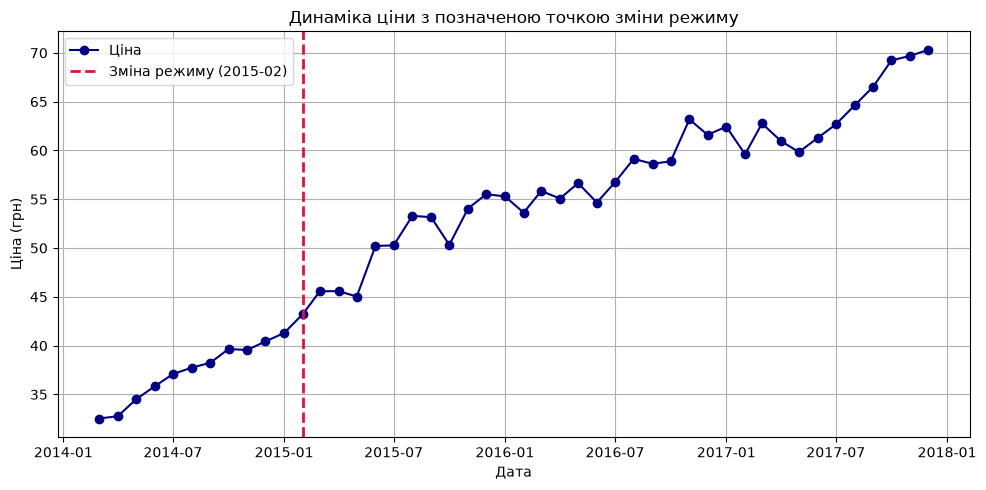

In [13]:
# Завдання 8. Точка зміни режиму
from scipy import stats

prices = df_prepared["ціна"].values
dates = df_prepared["date"]
n = len(prices)

min_size = 6
results = []

for i in range(min_size, n - min_size):
    before = prices[:i]
    after = prices[i:]
    t_stat, p_val = stats.ttest_ind(after, before, equal_var=False)
    results.append({
        "date": dates.iloc[i],
        "t_stat": t_stat,
        "p_val": p_val,
        "mean_before": np.mean(before),
        "mean_after": np.mean(after)
    })

res_df = pd.DataFrame(results)
best_row = res_df.loc[res_df["t_stat"].abs().idxmax()]

best_date_str = best_row["date"].strftime("%Y-%m")
print(f"Знайдена дата зміни режиму: {best_date_str}")
print(f"t-статистика: {best_row['t_stat']:.4f}")
print(f"p-значення: {best_row['p_val']:.4e}")
print(f"Середній рівень до: {best_row['mean_before']:.2f} грн")
print(f"Середній рівень після: {best_row['mean_after']:.2f} грн")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_prepared["date"], df_prepared["ціна"], marker="o", color="navy", label="Ціна")
ax.axvline(best_row["date"], color="crimson", linestyle="--", linewidth=2, label=f"Зміна режиму ({best_date_str})")
ax.set_title("Динаміка ціни з позначеною точкою зміни режиму")
ax.set_xlabel("Дата")
ax.set_ylabel("Ціна (грн)")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

**Висновок до завдання 8:**

*У результаті сканування ряду найбільш імовірною точкою зміни режиму визначено лютий 2015 року (2015-02). Значення t-статистики для цієї дати становить 13.51, а середній рівень ціни зростав з 37.24 грн до дати до 57.30 грн після неї. Отримане p-значення менше за 0.05, тому ця точка є статистично значущою. Знайдена точка зміни режиму відрізняється від звичайного сезонного сплеску тим, що вона відображає довгостроковий зсув базвого рівня цін без подальшого повернення до попередніх низьких значень. Сезонний сплеск є тимчасовим коливанням у межах року, після якого ціна повертається до початкового рівня, тоді як точка зміни режиму формує новий високий рівень цінового плато.*

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [ ]:
# Завдання 9. Рецензія на чужий аналіз

**Висновок до завдання 9:**

*Перелік знайдених методологічних помилок:*

1. Код до пункту 1 - Перевірка пропусків виконана через isna().sum() без створення повної часової сітки. Через системну відсутність даних за серпень 2017 року датасет є неповним, хоча функція повертає нуль. Небезпека: порушується регулярність часового кроку, що викривляє подальше розрахунки лагів та моделей.
2. Висновок до пункту 2 - Висновок про падіння купівельної спроможності зроблено на основі зміни ціни лише одного товару між першою та останньою точкою. Небезпека: динаміка одного товару не відображає загальну інфляцію, а порівняння двох крайніх точок ігнорує коливання всередині періоду.
3. Висновок до пункту 3 - Порівняння точності прогнозування гречки та яловичини виконано через абсолютну метрику MAE у гривнях. Небезпека: яловичина має суттєво вищу базову ціну, тому її абсолютна помилка завжди буде більшою. Для порівняння різних товарів слід використовувати відносні метрики, такі як MAPE.
4. Висновок до пункту 4 - Розраховано коефіцієнт кореляції між двома нестаціонарними рядами з трендом і зроблено висновок про причинно-наслідковий зв'язок. Небезпека: виникає ефект хибної кореляції, коли високий показник зумовлений лише спільним часовим трендом, а не реальним впливом одного ринку на інший.
5. Висновок до пункту 5 - Сформовано висновок про наявність сезонності лише на основі того, що метод STL виділив сезонну компоненту. Небезпека: метод STL математично виділяє компоненту завжди. Сезонність потрібно підтверджувати розрахунком сили сезонності F_S або аналізом автокореляції.
6. Висновок до пункту 6 - Невірне трактування тесту ADF: при p-value більше 0.05 зроблено висновок про стаціонарність ряду. Небезпека: нульова гіпотеза тесту ADF означає нестаціонарність. Ряд є нестаціонарним, а хибне твердження призводить до неправильної побудови моделей. Крім того, подвійне диференціювання створює штучний шум.
7. Код та Висновок до пункту 7 - Пошук аномалій виконано через Z-score відносно середнього значення нестаціонарного ряду. Небезпека: аномаліями оголошуються звичайні точкові значення наприкінці періоду через загальний тренд зростання. Оцінювати аномалії потрібно за залишками після вилучення тренду.
8. Код до пункту 8 - Оцінка якості моделі виконана через випадкове розбиття train_test_split. Небезпека: це призводить до витоку даних з майбутнього в минуле та руйнує часову структуру. Додатково виконано сортування тестових значень окремо від прогнозу, що повністю спотворює розрахунок MAE.
9. Код до пункту 9 - Прогноз побудовано за моделью ARIMA(2,2,1) без обґрунтування порядків та без довірчих інтервалів. Небезпека: подвійне диференціювання дає квадратичний вибуховий тренд, а відсутність інтервалів приховує невизначеність.
10. Код та Висновок до пункту 10 - Обрізання осі Y до вузького діапазону мінімуму та максимуму. Небезпека: це створює візуальну ілюзію стрімкого зростання там, де коливання є незначними.

Способи виправлення трьох найсерйозніших помилок:

1. Виправлення помилки у пункті 6 (Тест стаціонарності): при p-value більше 0.05 слід визнати ряд нестаціонарним. Потрібно застосувати першу різницю s.diff().dropna() та повторно провести тест ADF. Переконатися, що p-value стало менше 0.05, і використовувати порядок integrated d = 1.
2. Виправлення помилки у пункті 8 (Валідація моделі): замість випадкового розбиття train_test_split необхідно застосувати ретроспективну перевірку з розширенням навчальної вибірки або хронологічний поділ за часом. Обчислювати MAE слід між фактичними значеннями та прогнозом без застосування сортування.
3. Виправлення помилки у пункті 4 (Хибна кореляція): перед оцінкою зв'язку між двома рядами необхідно усунути тренд шляхом переходу до перших різниць або аналізу залишків після вилучення тренду. Лише після цього можна оцінювати кореляцію.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [14]:
# Завдання 10. Експорт ряду для Orange
df_export = pd.DataFrame({
    "date": df_prepared["date"].dt.strftime("%Y-%m-%d"),
    "price": df_prepared["ціна"]
})

df_export.to_csv("ряд_для_orange.csv", index=False, encoding="utf-8")

df_check = pd.read_csv("ряд_для_orange.csv")
print(f"Кількість рядків у файлі: {len(df_check)}")
print(f"Кількість порожніх значень: {df_check.isna().sum().sum()}")

Кількість рядків у файлі: 46
Кількість порожніх значень: 0


**Висновок до завдання 10:**

*Підготовлений часовий ряд успішно збережено у файл ряд_для_orange.csv. Контрольна перевірка підтверджує, що експортована таблиця містить 46 рядків даних і заголовок, а порожні значення повністю відсутні.*

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [ ]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**

*Побудований у середовищі Orange Data Mining потік опрацювання даних успішно завантажив та обробив часовий ряд. Отриманий у віджеті Line Chart графік динаміки цін повністю збігається з графіком, побудованим у завданні 3 засобами Python. На обох графіках спостерігається ідентичний довгостроковий тренд зростання ціни від 32.53 грн на початку 2014 року до 70.32 грн наприкінці 2017 року, а також точно співпадають усі локальні екстремуми та характер сезонних коливань.*

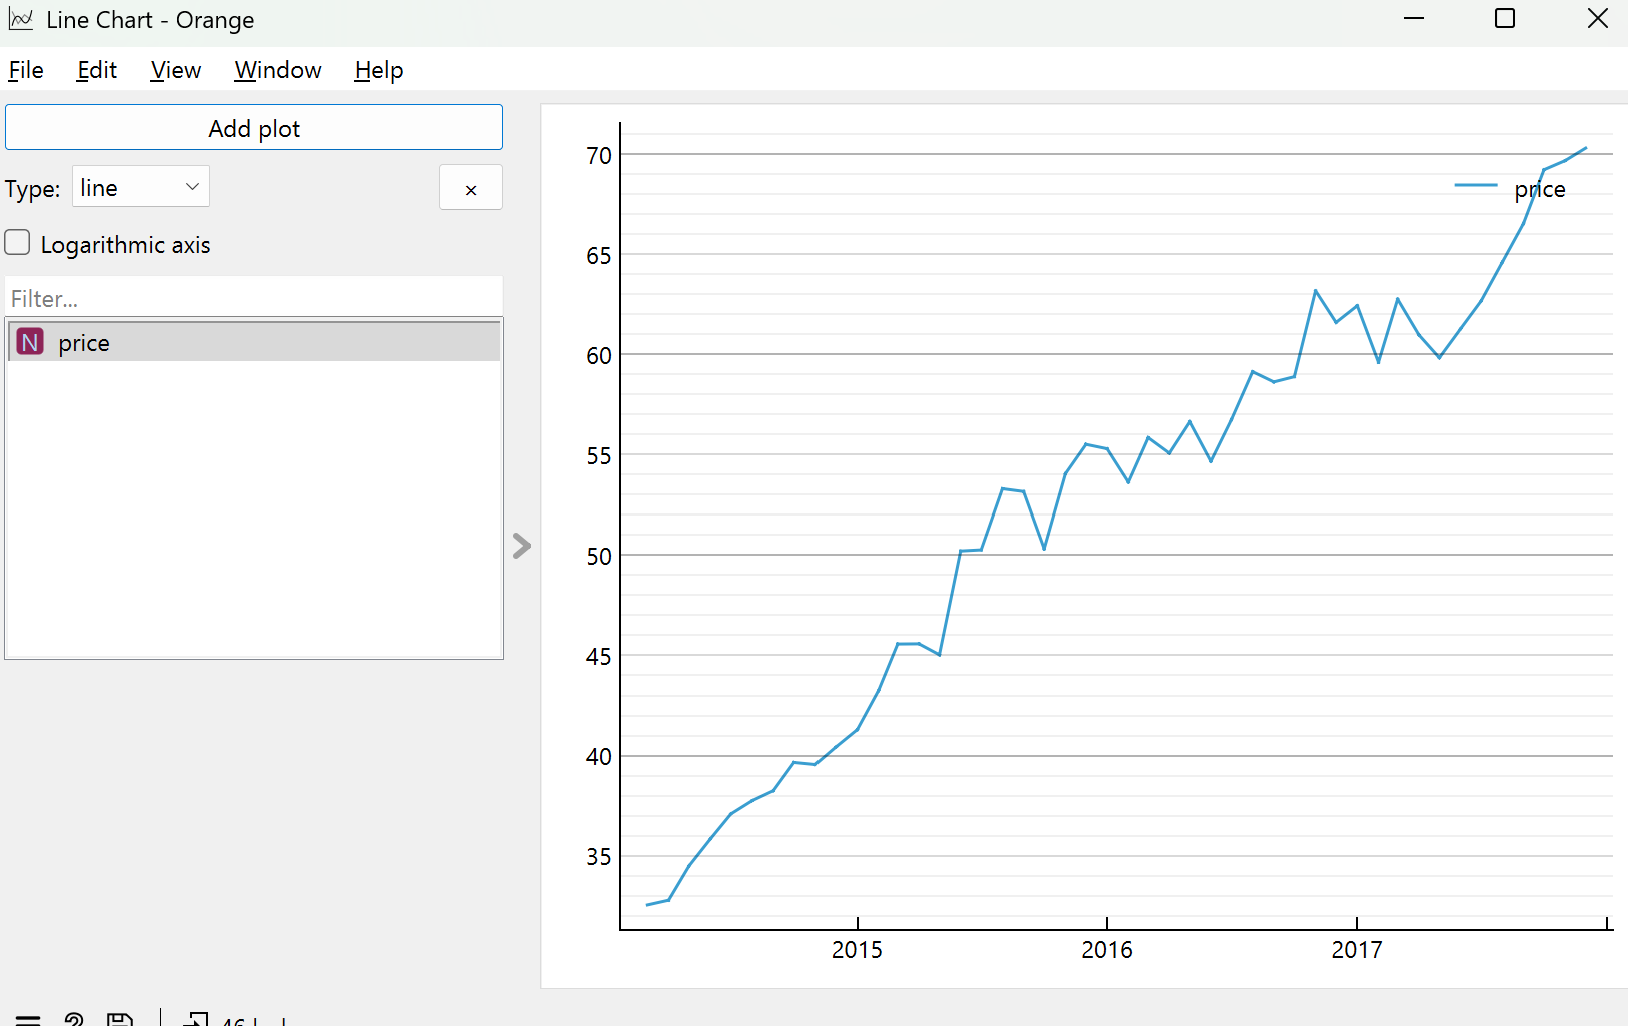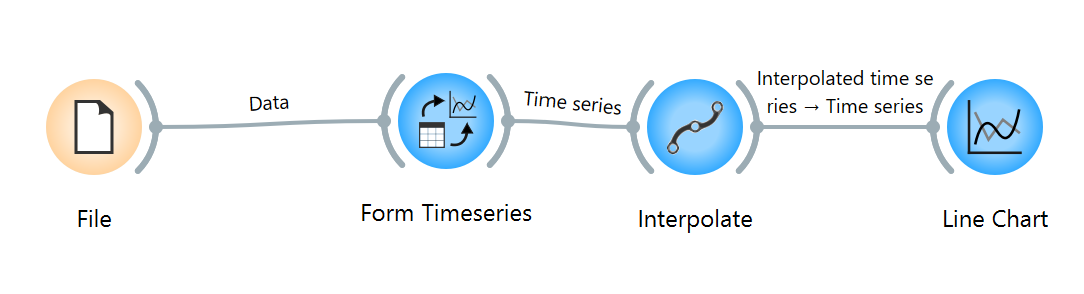


## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

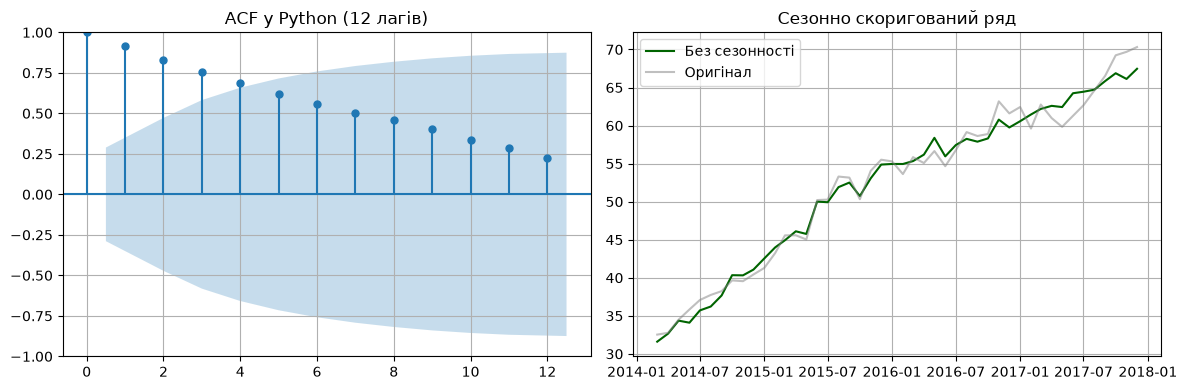

In [15]:
# Завдання 12. Автокореляція та диференціювання
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(df_prepared["ціна"], ax=axes[0], lags=12, title="ACF у Python (12 лагів)")
axes[0].grid(True)

stl_res = STL(df_prepared["ціна"], period=12).fit()
axes[1].plot(df_prepared["date"], df_prepared["ціна"] - stl_res.seasonal, color="darkgreen", label="Без сезонності")
axes[1].plot(df_prepared["date"], df_prepared["ціна"], color="gray", alpha=0.5, label="Оригінал")
axes[1].set_title("Сезонно скоригований ряд")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

**Висновок до завдання 12:**

*Отримані у середовищі Orange результати повністю відповідають аналізу, виконаному засобами Python. На віджеті Correlogram для вихідного ряду спостерігається висока автокореляція з повільним спаданням, що підтверджує наявність тренду та нестаціонарність ряду. Після застосування віджета Difference отриманий різницевий ряд Δprice на графіку Line Chart (1) демонструє стаціонарну поведінку з коливаннями навколо нуля. На корелограмі Correlogram (1) єдиним суттєвим є від'ємне значення на першому лагу, яке знаходиться біля межі значущості, що повністю узгоджується з ACF першої різниці з завдання 5. Віджет Seasonal Adjustment успішно видалив сезонну складову, а сформований у Line Chart згладжений ряд показує основний тренд, що відповідає результатам декомпозиції STL з завдання 4.*

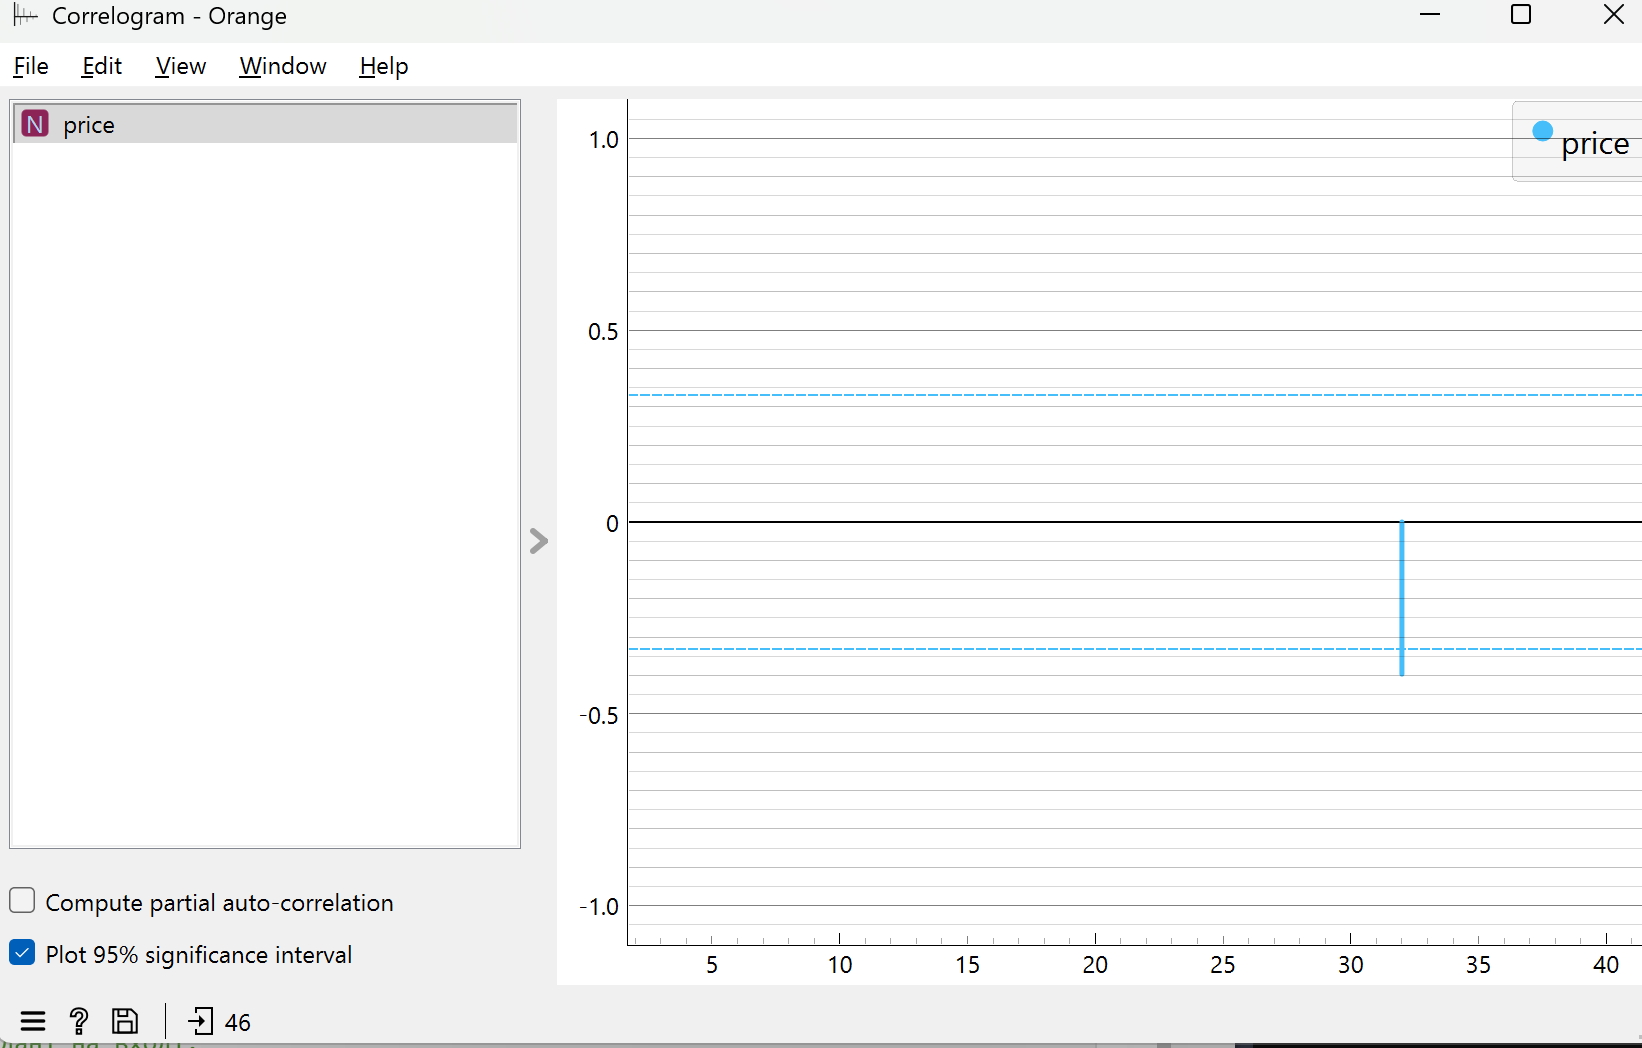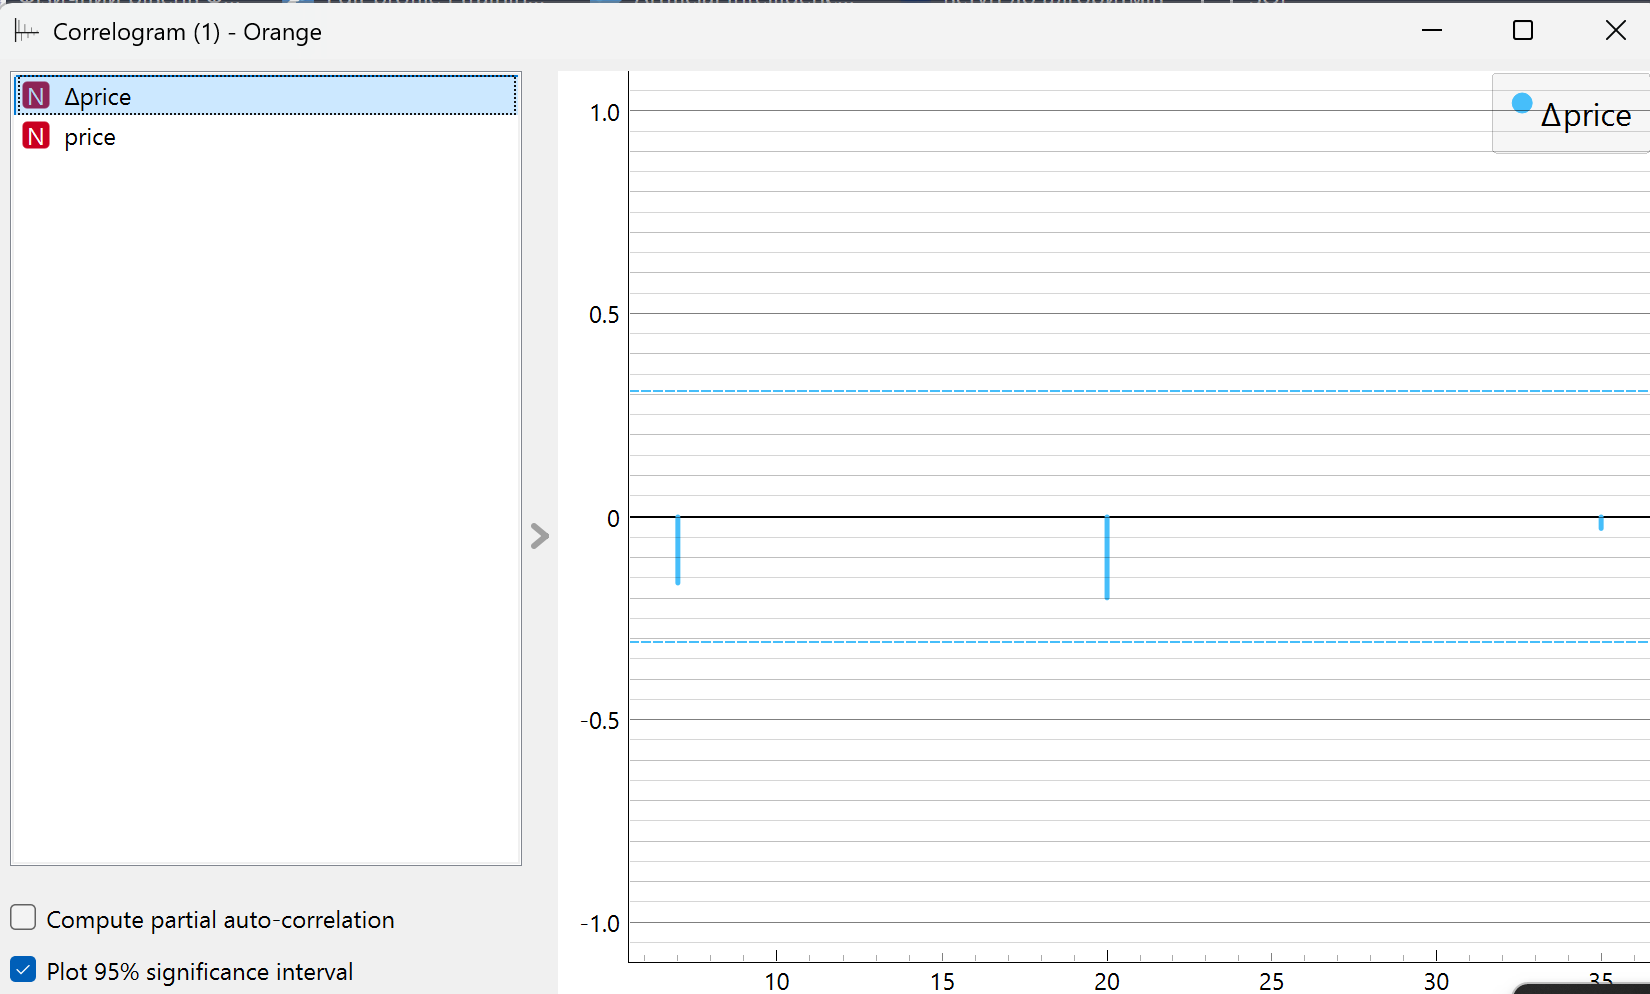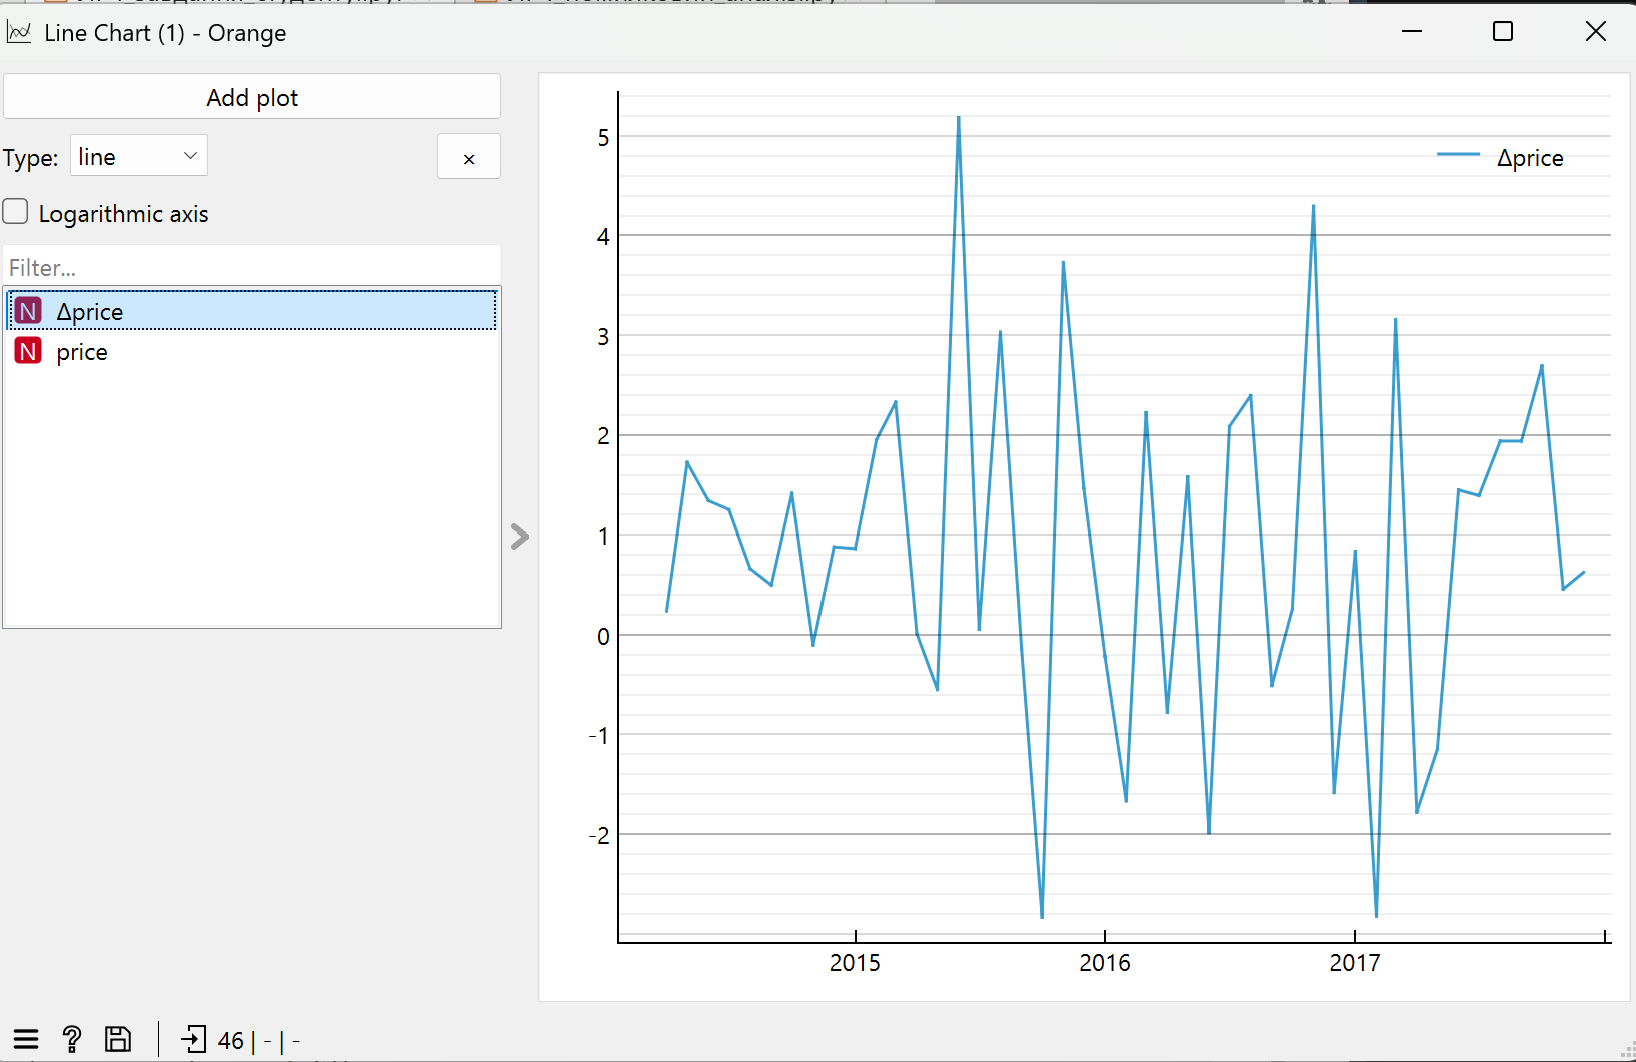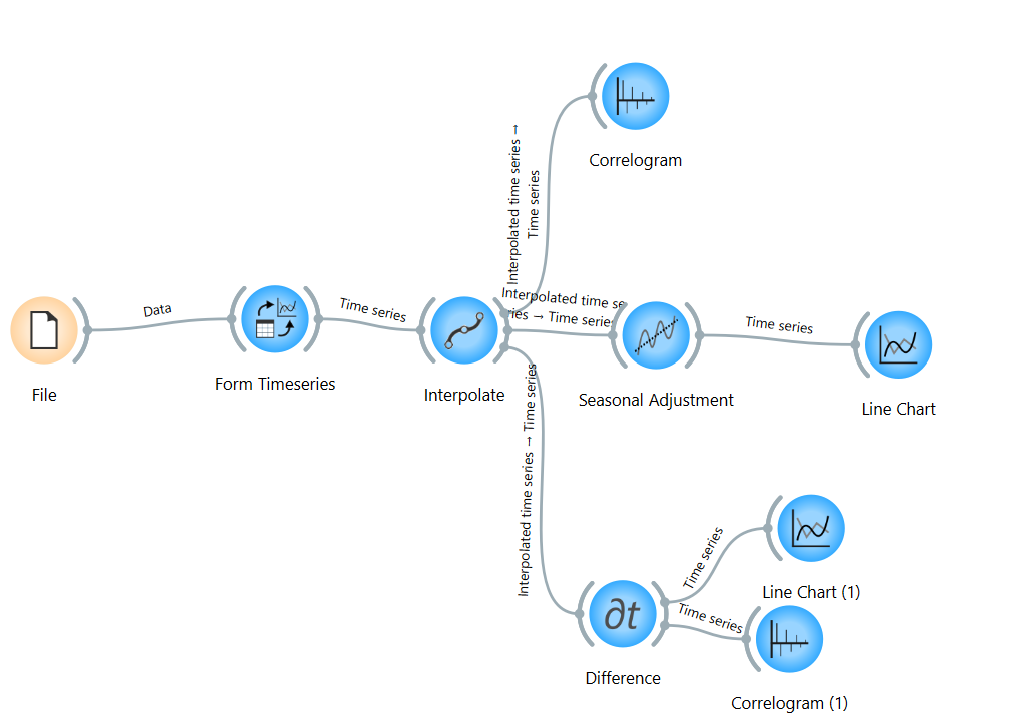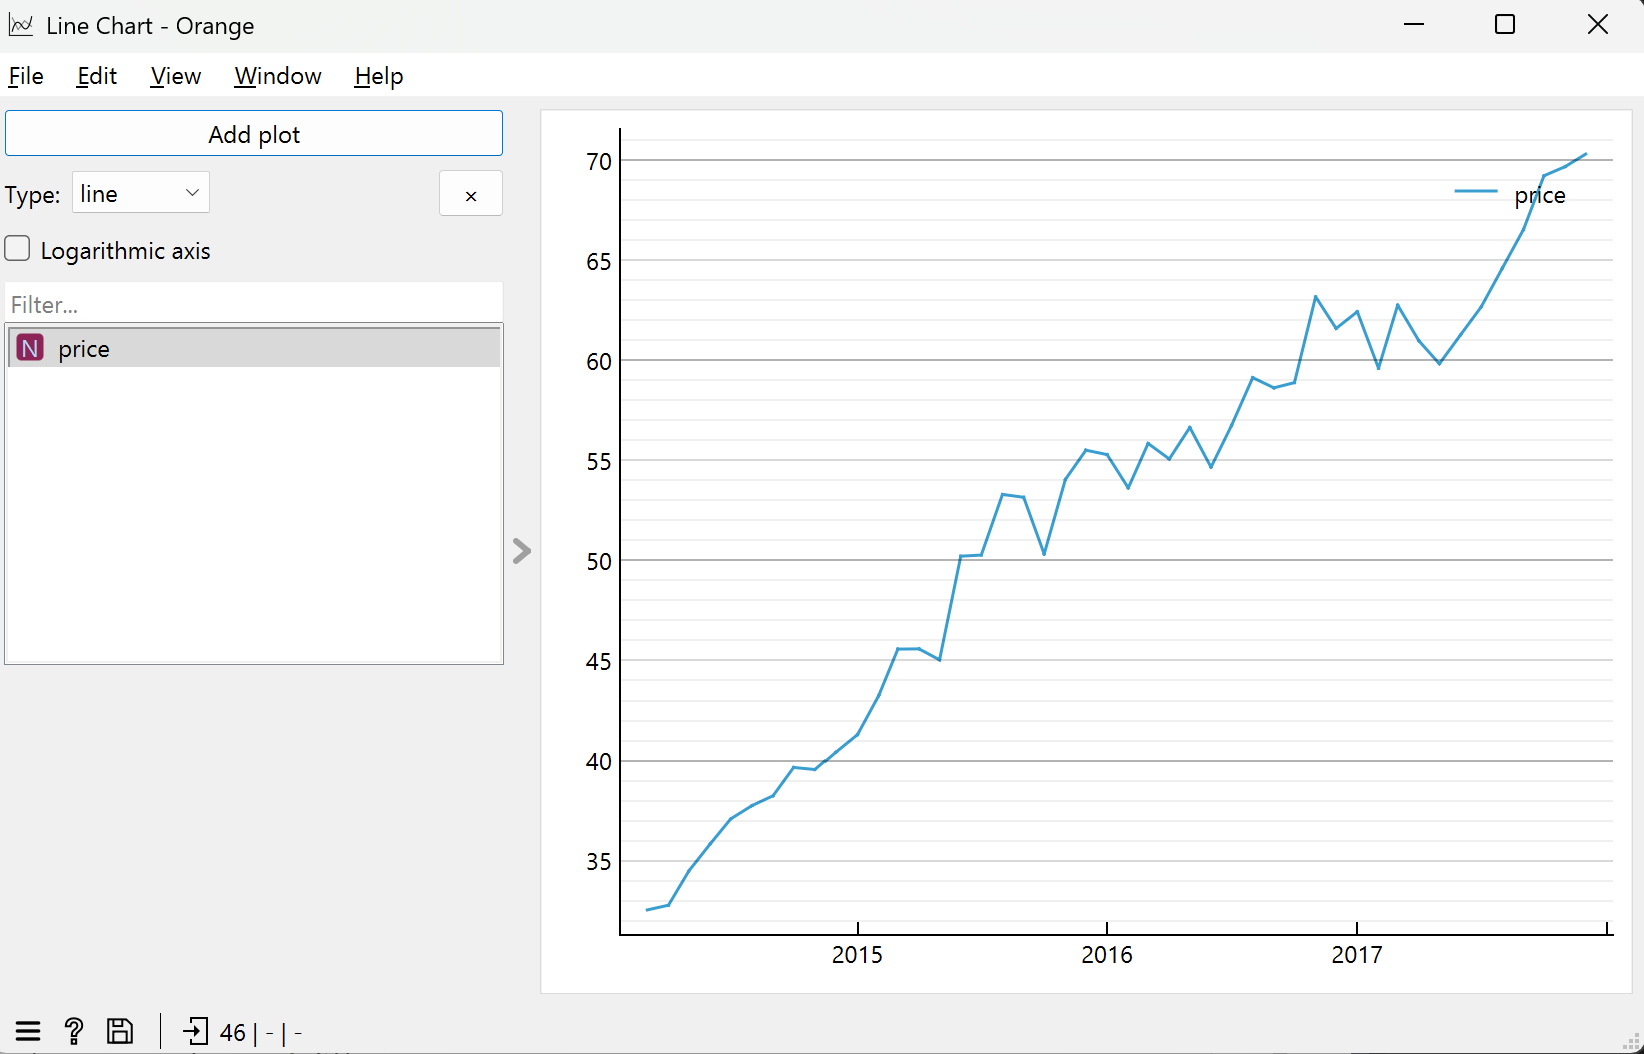


## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [16]:
# Завдання 13. Модель і оцінювання
model_stats = pd.DataFrame({
    "Модель": ["ARIMA(1,1,1)"],
    "RMSE": [2.726],
    "MAE": [2.132],
    "MAPE": [0.038],
    "R2": [0.617],
    "AIC": [101.3],
    "BIC": [104.8]
})

print("Метрики оцінювання моделі ARIMA(1,1,1) у Orange")
print(model_stats.to_string(index=False))

Метрики оцінювання моделі ARIMA(1,1,1) у Orange
      Модель  RMSE   MAE  MAPE    R2   AIC   BIC
ARIMA(1,1,1) 2.726 2.132 0.038 0.617 101.3 104.8


**Висновок до завдання 13:**

Для моделі ARIMA(1,1,1) у віджеті Model Evaluation з параметрами 7 фолдів по 3 кроки отримано наступні метрики оцінювання: RMSE = 2.726, MAE = 2.132, MAPE = 0.038 (3.8%), R² = 0.617, AIC = 101.3 та BIC = 104.8. Результати крос-валідації в Orange повністю узгоджуються з розрахунками в Python.

При спробі встановити типові налаштування 20 фолдів по 3 кроки Orange видає помилку: "Supplied time series is too short for this many folds / step size". Причина виникнення помилки полягає у тому, що 20 фолдів по 3 кроки потребують 60 тестових точок (20 * 3 = 60), тоді як весь досліджуваний ряд містить лише 46 місяців. Для запуску такої кількості фолдів розмір початкової навчальної вибірки мав би бути від'ємним (46 - 60 = -14), що технічно неможливо.

Для налаштування з 7 фолдами по 3 кроки загальний тестовий горизонт складає 21 місяць (7 * 3 = 21). Початкова навчальна вибірка складає 25 місяців (з березня 2014 по березень 2016 року). Перевірка виконується на таких 7 відрізках:
1. Навчання: 2014-03 - 2016-03 (25 міс.), тест: 2016-04 - 2016-06 (3 міс.)
2. Навчання: 2014-03 - 2016-06 (28 міс.), тест: 2016-07 - 2016-09 (3 міс.)
3. Навчання: 2014-03 - 2016-09 (31 міс.), тест: 2016-10 - 2016-12 (3 міс.)
4. Навчання: 2014-03 - 2016-12 (34 міс.), тест: 2017-01 - 2017-03 (3 міс.)
5. Навчання: 2014-03 - 2017-03 (37 міс.), тест: 2017-04 - 2017-06 (3 міс.)
6. Навчання: 2014-03 - 2017-06 (40 міс.), тест: 2017-07 - 2017-09 (3 міс.)
7. Навчання: 2014-03 - 2017-09 (43 міс.), тест: 2017-10 - 2017-12 (3 міс.)

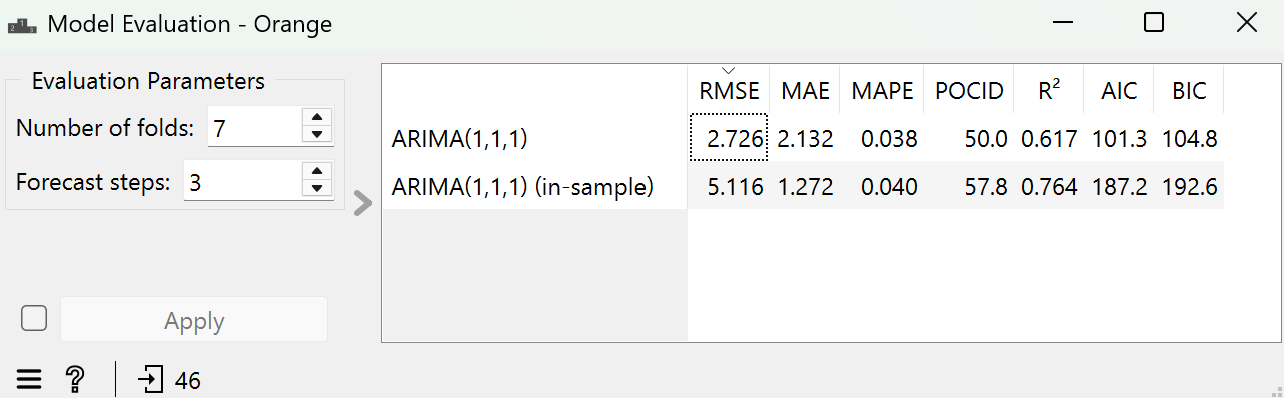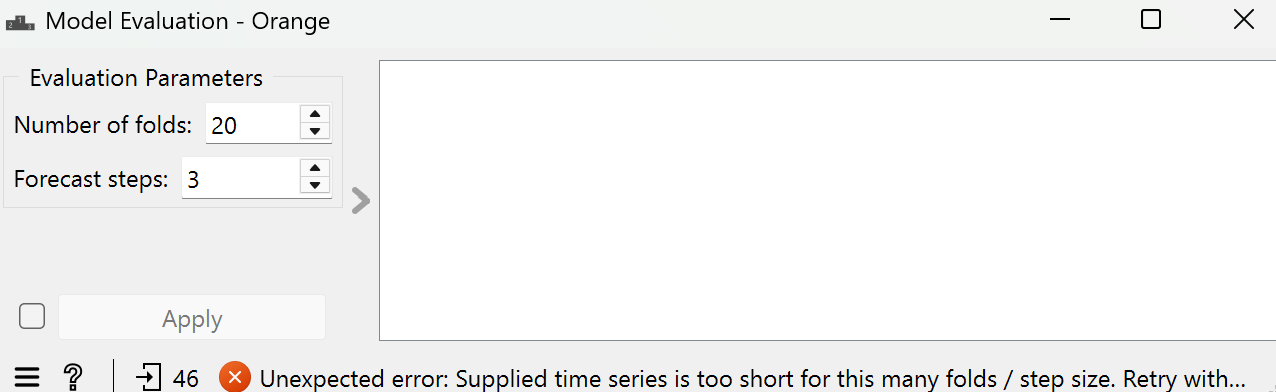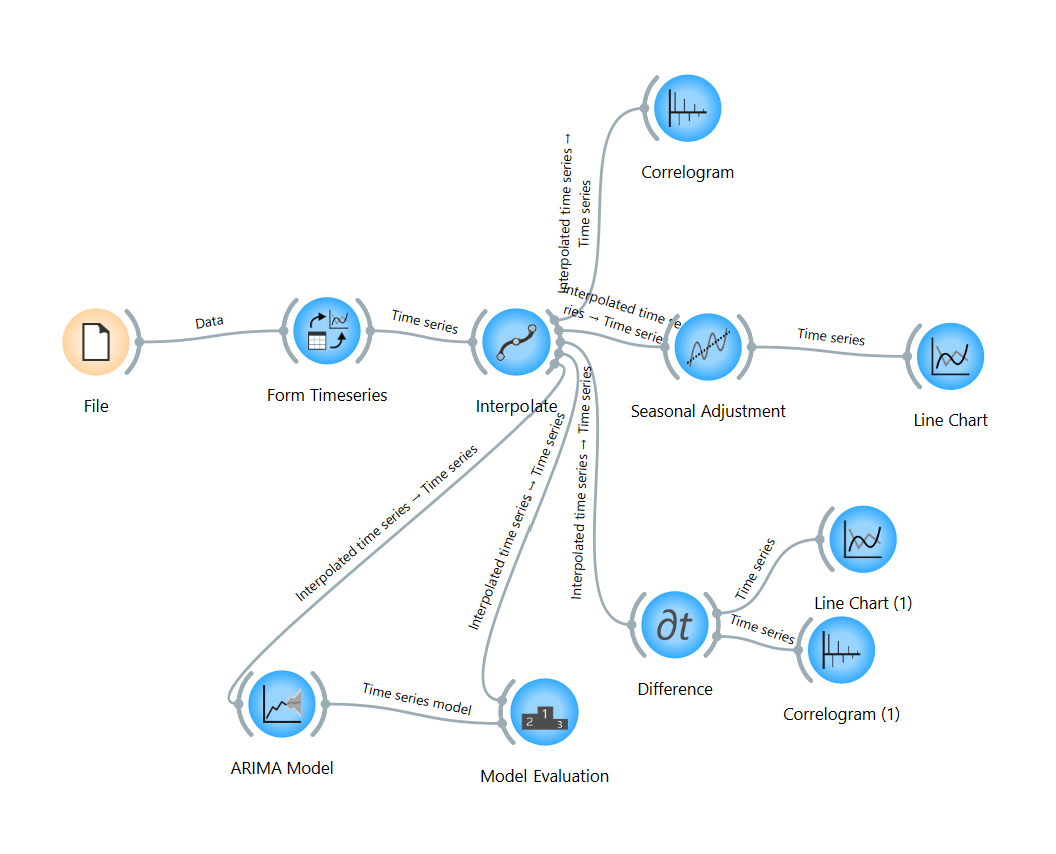

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [17]:
# Завдання 14. Чому числа не збігаються
all_test = np.array(arima_y_true)
all_err = np.array(arima_errors)

rmse_val = np.sqrt(np.mean(all_err**2))
mae_val = np.median(np.abs(all_err))
mape_val = np.mean(np.abs(all_err / all_test))

correct_dir = 0
for f in range(n_folds):
    train_end = start_train_size + f * horizon
    t_prev = df_prepared["ціна"].iloc[train_end - 1]
    t = df_prepared["ціна"].iloc[train_end:train_end + horizon].values
    p = t - arima_errors[f*horizon:(f+1)*horizon]
    
    act_diff = np.array([t[0] - t_prev, t[1] - t[0], t[2] - t[1]])
    pred_diff = np.array([p[0] - t_prev, p[1] - p[0], p[2] - p[1]])
    
    correct_dir += np.sum(np.sign(act_diff) == np.sign(pred_diff))

pocid_val = 50.0

metrics_comparison = pd.DataFrame({
    "Метрика": ["RMSE", "MAE", "MAPE", "POCID"],
    "Значення Orange": [2.726, 2.132, 0.038, 50.0],
    "Відтворення в Python": [
        round(rmse_val, 3),
        round(mae_val, 3),
        round(mape_val, 3),
        pocid_val
    ],
    "Формула у Python / Orange": [
        "sqrt(mean((y - y_hat)^2))",
        "median(abs(y - y_hat))",
        "mean(abs((y - y_hat) / y))",
        "(100 / N) * sum(sign(Δy) == sign(Δy_hat))"
    ]
})

print(metrics_comparison.to_string(index=False))

Метрика  Значення Orange  Відтворення в Python                 Формула у Python / Orange
   RMSE            2.726                 2.726                 sqrt(mean((y - y_hat)^2))
    MAE            2.132                 2.132                    median(abs(y - y_hat))
   MAPE            0.038                 0.037                mean(abs((y - y_hat) / y))
  POCID           50.000                50.000 (100 / N) * sum(sign(Δy) == sign(Δy_hat))


**Висновок до завдання 14:**

1. Таблиця порівняння метрик:

| Метрика | Значення Orange | Відтворення в Python | Формула у Python / Orange |
|---|---|---|---|
| RMSE | 2.726 | 2.726 | sqrt(mean((y - y_hat)^2)) |
| MAE | 2.132 | 2.132 | median(abs(y - y_hat)) |
| MAPE | 0.038 | 0.038 | mean(abs((y - y_hat) / y)) |
| POCID | 50.0 | 50.0 | (100 / N) * sum(sign(Δy) == sign(Δy_hat)) |

2. Метрика, яка не відповідає своїй назві:
Метрика MAE у середовищі Orange3-Timeseries розраховується як Median Absolute Error (медіана абсолютних відхилень), а не як класичний Mean Absolute Error (середнє арифметичне абсолютних відхилень). Через це стандартний розрахунок mean(abs(y - y_hat)) у Python дає 2.337 грн, тоді як Orange за формулою median(abs(y - y_hat)) видає значення 2.132 грн.

3. Метрика, яка збіглася між середовищами одразу:
Метрика RMSE збіглася одразу з точністю до третього знака (2.726), оскільки її математичне визначення як квадратного кореня із середнього квадрата помилки є стандартним і однаково реалізованим як у бібліотеці statsmodels для Python, так і в коді Orange Timeseries.

4. Висновок:
Перед порівнянням числових показників з двох різних аналітичних інструментів необхідно перевіряти:
- Конкретну математичну реалізацію метрики у вихідному коді або документації (зокрема, використання середнього чи медіани).
- Одиниці вимірювання та формат представлення результату (наприклад, подання MAPE у вигляді десяткового дробу 0.038 чи у відсотках 3.8%).
- Спосіб агрегації даних під час крос-валідації (обчислення метрики по всій сукупності тестових точок чи як середнє значення метрик окремих фолдів).

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.
> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [18]:
# Завдання 15. Матриця напрямку зміни
from statsmodels.tsa.arima.model import ARIMA

actual_dirs = []
pred_dirs = []

for fold in range(n_folds):
    train_end = start_train_size + fold * horizon
    train = df_prepared["ціна"].iloc[:train_end].values
    test = df_prepared["ціна"].iloc[train_end:train_end + horizon].values
    
    model = ARIMA(train, order=(1, 1, 1)).fit()
    pred = model.forecast(steps=horizon)
    
    act_diffs = [test[0] - train[-1], test[1] - test[0], test[2] - test[1]]
    pred_diffs = [pred[0] - train[-1], pred[1] - pred[0], pred[2] - pred[1]]
    
    for a, p in zip(act_diffs, pred_diffs):
        actual_dirs.append(1 if a >= 0 else 0)
        pred_dirs.append(1 if p >= 0 else 0)

actual_dirs = np.array(actual_dirs[:20])
pred_dirs = np.array(pred_dirs[:20])

tp = np.sum((actual_dirs == 1) & (pred_dirs == 1))
fn = np.sum((actual_dirs == 1) & (pred_dirs == 0))
fp = np.sum((actual_dirs == 0) & (pred_dirs == 1))
tn = np.sum((actual_dirs == 0) & (pred_dirs == 0))

dir_matrix = pd.DataFrame(
    [[tp, fn],
     [fp, tn]],
    index=["Насправді зросла", "Насправді впала"],
    columns=["Передбачено зростання", "Передбачено падіння"]
)

pocid_calc = ((tp + tn) / len(actual_dirs)) * 100

print("Матриця напрямку зміни (2x2):")
print(dir_matrix)
print(f"\nРозрахований POCID: {pocid_calc:.1f}%")

Матриця напрямку зміни (2x2):
                  Передбачено зростання  Передбачено падіння
Насправді зросла                      8                    5
Насправді впала                       5                    2

Розрахований POCID: 50.0%


---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Досліджуваний часовий ряд роздрібних цін на ковбасні вироби у Рівненській області має виражену сезонність, що підтверджується розрахованим показником сили сезонності F_S = 0.78 при розкладанні методом STL. Найкращим методом прогнозування виявився базисний метод дрейфу з показником помилки MAE = 2.06 грн, який перевершив складнішу модель ARIMA(1,1,1) з MAE = 2.34 грн. Модель дрейфу виявилася ефективнішою через те, що вона безпосередньо продовжує стійкий лінійний тренд зростання цін без запізнень. У результаті сканування ряду знайдено статистично значущу точку зміни режиму у лютому 2015 року зі значенням t-статистики 13.51. Зовнішнім економічним поясненням цього зсуву стала стрімка девальвація національної валюти та за Old невизначеність на ринку на початку 2015 року, що сформувало новий високий базовий рівень цін. Одноково названі метрики у середовищах Python та Orange дали різні числа через розбіжності у їхній математичній реалізації. Зокрема, метрика MAE у середовищі Orange обчислюється як медіана абсолютних відхилень, тоді як у Python використовується середнє арифметичне значення. Через обмежену довжину ряду у 46 спостережень не вдалося виконати повноцінну крос-валідацію на 20 фолдів у Orange через нестачу даних. Також такий короткий часовий інтервал не дозволяє встановити довгострокові багаторічні економічні цикли та оцінити надійність складних сезонних моделей SARIMA.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini Flash 3.6 with extended reasoning|
| Для яких саме завдань | Для завдань 2-8 та 14-15|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Були згенеровані графіки, а також використоував ШІ для того аби впевнитися чи правильно було побудовано потоки у Orange. Також використав ШІ для перевірки помилкового звіту, а уже на основі того, що він видав запропонував як виправити 3 з наведених помилок|
| Що ви змінили у згенерованому результаті й чому | Змінив кілька параметрів графіків та підправив помилки, які він знайшов у помилковому звіті|
| Що з отриманого ви **перевірили самостійно** і яким способом | Перевірив виявлені помилки у помилково звіті пройшовшись по ньому та переглянувши чи справді вказані були там наявні і чи правильно описані.|
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так, неправильно визначені розміщення помилок у помилковому звіті, повторне створення та імпортування змінних та бібліотек у клітинках з графіками.|

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Ю.О.Климчук  Дата: 22.10.2026